In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler  #Normalization

In [3]:
df = pd.read_csv('train1.csv')

In [4]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Dataset information
df.info()

# Statistical summary of numerical variables
df.describe()

Number of rows: 891
Number of columns: 12
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
# Identify numerical and categorical columns

numerical_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(include=['object']).columns

print("Numerical columns:")
print(list(numerical_columns))

print("\nCategorical columns:")
print(list(categorical_columns))

Numerical columns:
['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

Categorical columns:
['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


In [6]:
# Missing-value analysis

missing_count = df.isnull().sum()
missing_percentage = (df.isnull().mean() * 100).round(2)

missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage': missing_percentage
})

missing_summary = missing_summary[missing_summary['Missing Count'] > 0]

missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

,Missing Count,Missing Percentage
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


### Missing Value Analysis

The dataset contains missing observations in Age, Cabin and Embarked.

Cabin contains a very high proportion of missing values (approximately 77.10%), making direct imputation unreliable. Therefore, the Cabin column is removed.

Age contains approximately 19.87% missing observations. Since Age is a numerical variable, the missing values are imputed using a central tendency measure.

Embarked contains only a very small number of missing observations and is imputed using the mode because it is a categorical variable.

In [7]:
df.drop(columns=['Cabin'],inplace=True)

In [8]:
df['Age'] = df['Age'].fillna(df['Age'].mean())

In [9]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [10]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

print("Missing values in Embarked:", df['Embarked'].isnull().sum())

# Display category distribution
print(df['Embarked'].value_counts())

Missing values in Embarked: 0
Embarked
S    646
C    168
Q     77
Name: count, dtype: int64


In [11]:
df['Embarked'].value_counts()

Embarked
S    646
C    168
Q     77
Name: count, dtype: int64

In [12]:
# EDA
# Target Variable Analysis

print("Survival counts:")
print(df['Survived'].value_counts())

print("\nSurvival percentages:")
print(
    (df['Survived'].value_counts(normalize=True) * 100).round(2)
)

Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival percentages:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


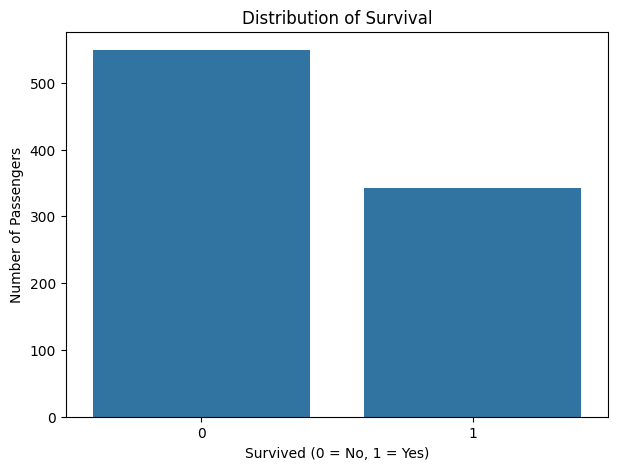

In [13]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='Survived'
)

plt.title('Distribution of Survival')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')

plt.show()

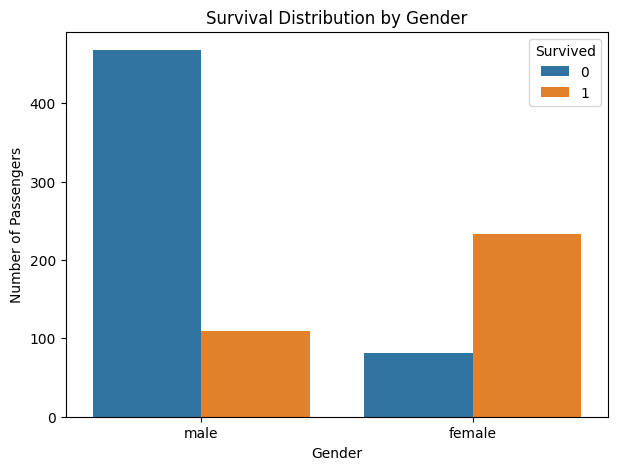

In [14]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='Sex',
    hue='Survived'
)

plt.title('Survival Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Passengers')

plt.show()

In [15]:
gender_survival = (
    df.groupby('Sex')['Survived']
      .mean()
      .mul(100)
      .round(2)
)

print("Survival percentage by gender:")
print(gender_survival)

Survival percentage by gender:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


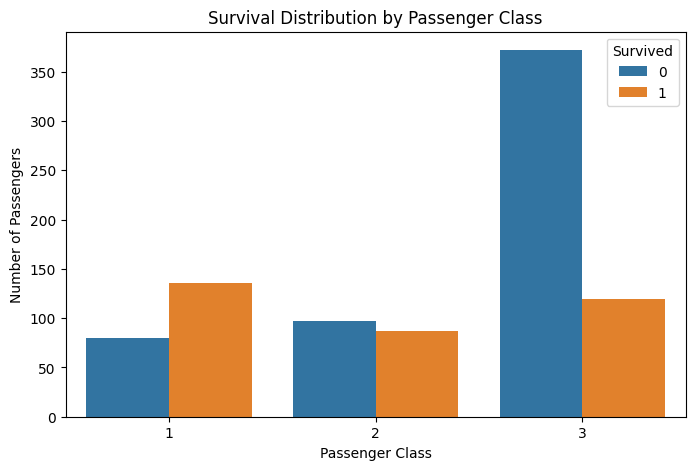

In [16]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='Pclass',
    hue='Survived'
)

plt.title('Survival Distribution by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Number of Passengers')

plt.show()

In [17]:
class_survival = (
    df.groupby('Pclass')['Survived']
      .mean()
      .mul(100)
      .round(2)
)

print("Survival percentage by passenger class:")
print(class_survival)

Survival percentage by passenger class:
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


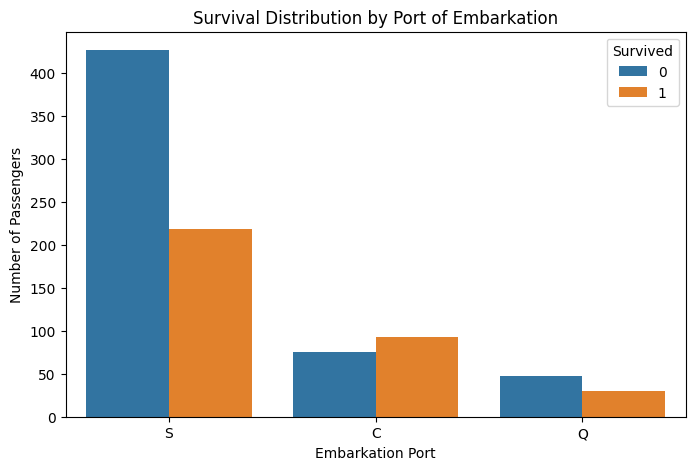

In [18]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='Embarked',
    hue='Survived'
)

plt.title('Survival Distribution by Port of Embarkation')
plt.xlabel('Embarkation Port')
plt.ylabel('Number of Passengers')

plt.show()

In [19]:
embarked_survival = (
    df.groupby('Embarked')['Survived']
      .mean()
      .mul(100)
      .round(2)
)

print("Survival percentage by embarkation port:")
print(embarked_survival)

Survival percentage by embarkation port:
Embarked
C    55.36
Q    38.96
S    33.90
Name: Survived, dtype: float64


In [20]:
print("Age Statistics")
print("----------------")
print("Minimum Age:", df['Age'].min())
print("Maximum Age:", df['Age'].max())
print("Mean Age:", round(df['Age'].mean(), 2))
print("Median Age:", round(df['Age'].median(), 2))
print("Standard Deviation:", round(df['Age'].std(), 2))
print("Skewness:", round(df['Age'].skew(), 2))

Age Statistics
----------------
Minimum Age: 0.42
Maximum Age: 80.0
Mean Age: 29.7
Median Age: 29.7
Standard Deviation: 13.0
Skewness: 0.43


(array([100., 523., 188.,  69.,  11.]),
 array([ 0.42 , 16.336, 32.252, 48.168, 64.084, 80.   ]),
 <BarContainer object of 5 artists>)

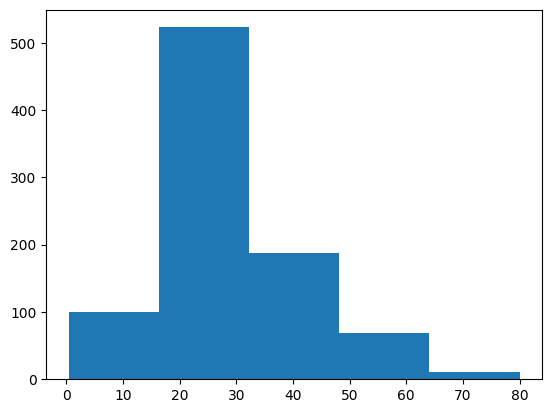

In [21]:
plt.hist(df['Age'],bins=5)

<Axes: xlabel='Age', ylabel='Count'>

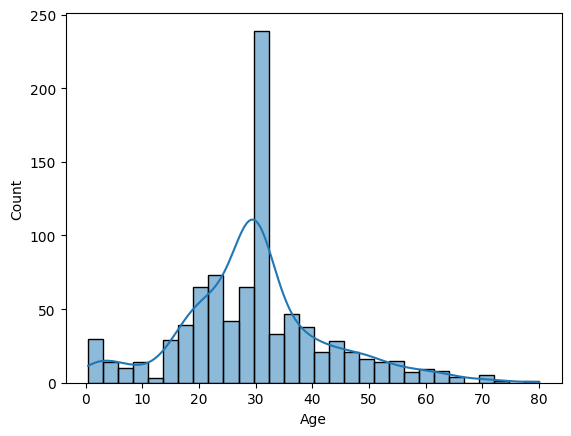

In [22]:
sns.histplot(df['Age'],kde=True)

<Axes: ylabel='Age'>

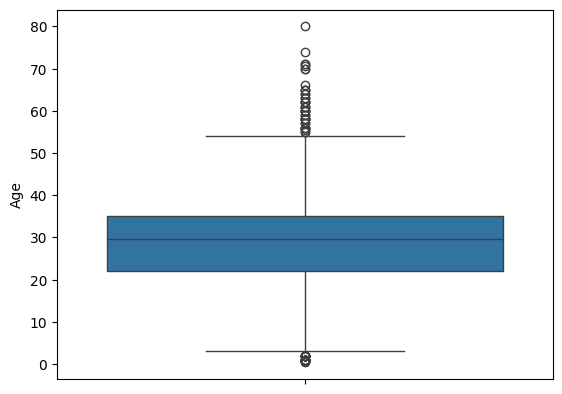

In [23]:
sns.boxplot(df['Age'])

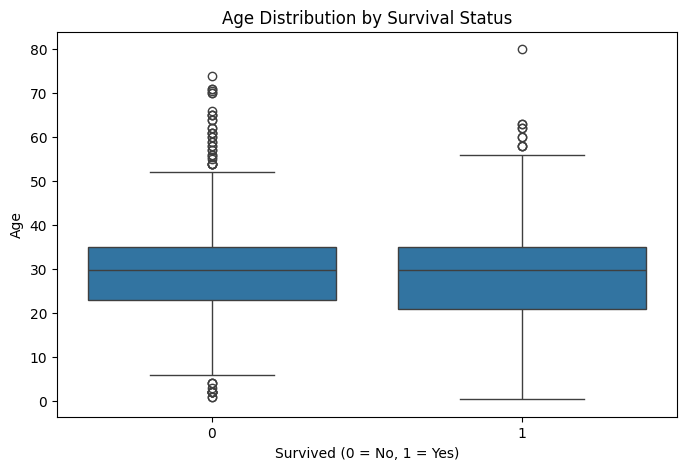

In [24]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='Survived',
    y='Age'
)

plt.title('Age Distribution by Survival Status')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Age')

plt.show()

In [25]:
print(
    df.groupby('Survived')['Age']
      .agg(['count', 'mean', 'median', 'min', 'max'])
      .round(2)
)

          count   mean  median   min   max
Survived                                  
0           549  30.42    29.7  1.00  74.0
1           342  28.55    29.7  0.42  80.0


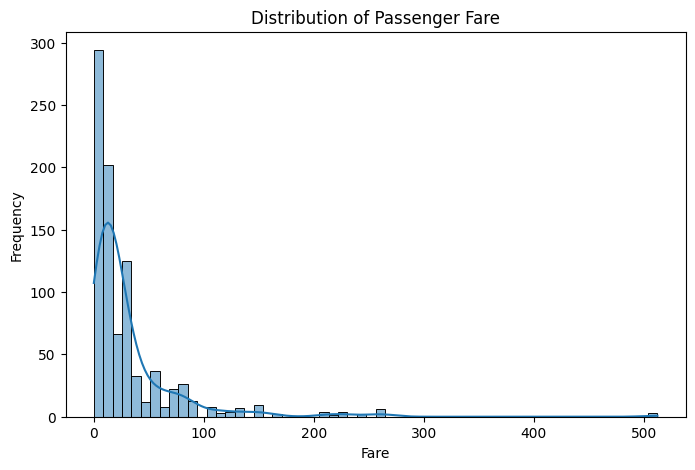

In [26]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='Fare',
    kde=True
)

plt.title('Distribution of Passenger Fare')
plt.xlabel('Fare')
plt.ylabel('Frequency')

plt.show()

In [27]:
print(
    df['Fare'].describe()
)

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64


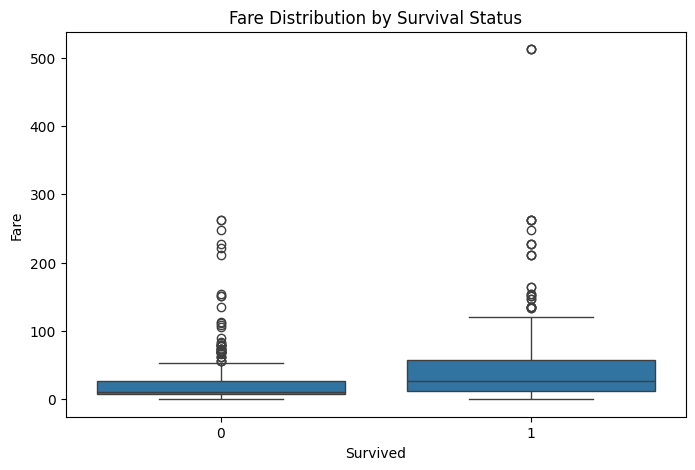

In [28]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='Survived',
    y='Fare'
)

plt.title('Fare Distribution by Survival Status')
plt.xlabel('Survived')
plt.ylabel('Fare')

plt.show()

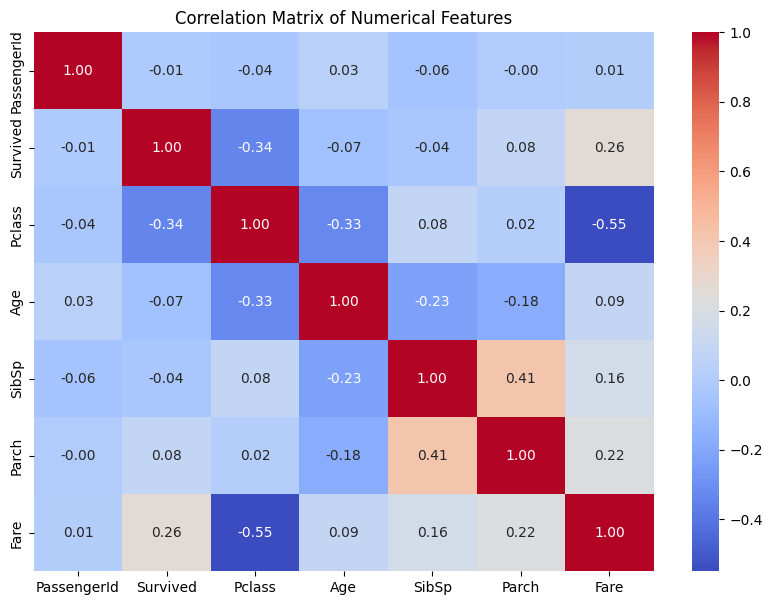

In [29]:
# Correlation Analysis

numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(10,7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Matrix of Numerical Features')

plt.show()

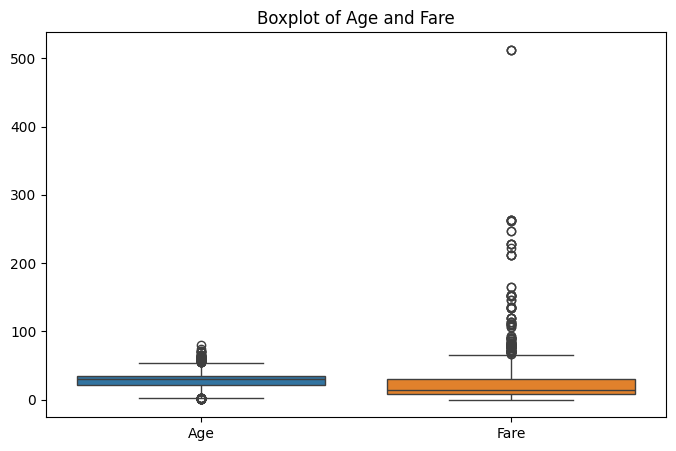

In [30]:
# Outlier analysis
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df[['Age', 'Fare']]
)

plt.title('Boxplot of Age and Fare')

plt.show()

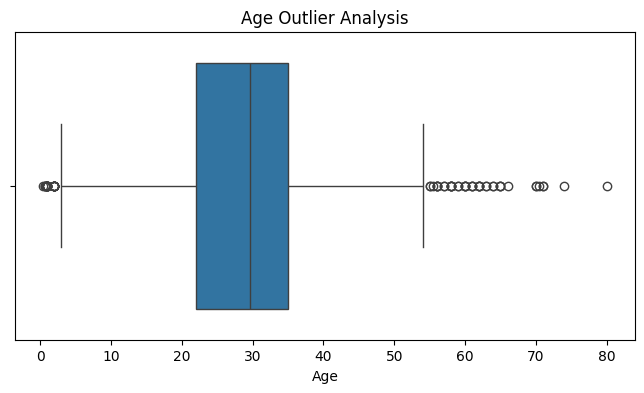

In [31]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df['Age'])

plt.title('Age Outlier Analysis')
plt.xlabel('Age')

plt.show()

In [32]:
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

df[['SibSp', 'Parch', 'FamilySize']].head()

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


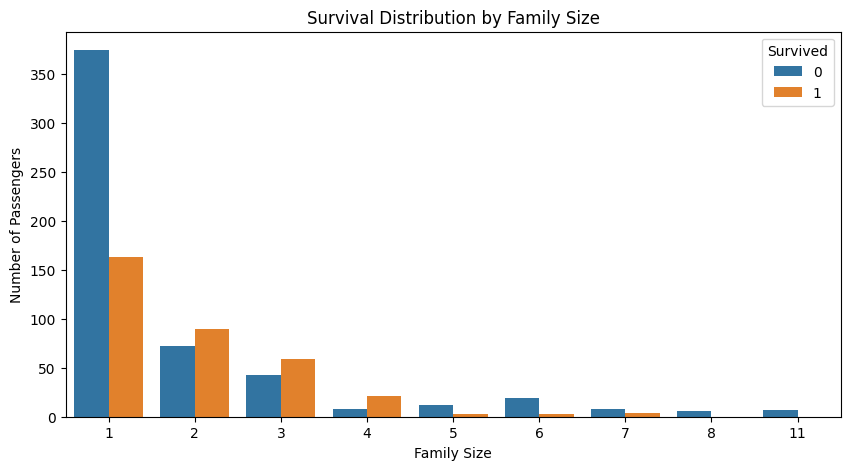

In [33]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x='FamilySize',
    hue='Survived'
)

plt.title('Survival Distribution by Family Size')
plt.xlabel('Family Size')
plt.ylabel('Number of Passengers')

plt.show()

In [34]:
family_survival = (
    df.groupby('FamilySize')['Survived']
      .mean()
      .mul(100)
      .round(2)
)

print("Survival percentage by family size:")
print(family_survival)

Survival percentage by family size:
FamilySize
1     30.35
2     55.28
3     57.84
4     72.41
5     20.00
6     13.64
7     33.33
8      0.00
11     0.00
Name: Survived, dtype: float64


In [35]:
# One-Hot Encoding of categorical variables

df_encoded = pd.get_dummies(
    df,
    columns=['Sex', 'Embarked'],
    drop_first=False,
    dtype=int
)

print("Dataset shape before encoding:", df.shape)
print("Dataset shape after encoding:", df_encoded.shape)

df_encoded.head()

Dataset shape before encoding: (891, 12)
Dataset shape after encoding: (891, 15)


,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,FamilySize,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,2,0,1,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,2,1,0,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,1,1,0,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,2,1,0,0,0,1
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,1,0,1,0,0,1


In [36]:
#categorical variables before and after encoding

print("Original categorical columns:")
print(df[['Sex', 'Embarked']].head())

print("\nEncoded columns:")
print(
    df_encoded[
        ['Sex_female', 'Sex_male',
         'Embarked_C', 'Embarked_Q', 'Embarked_S']
    ].head()
)

Original categorical columns:
      Sex Embarked
0    male        S
1  female        C
2  female        S
3  female        S
4    male        S

Encoded columns:
   Sex_female  Sex_male  Embarked_C  Embarked_Q  Embarked_S
0           0         1           0           0           1
1           1         0           1           0           0
2           1         0           0           0           1
3           1         0           0           0           1
4           0         1           0           0           1


### Interpretation of One-Hot Encoding

One-Hot Encoding converts categorical variables into binary numerical features.

For example:

- `Sex_female = 1` indicates that the passenger is female.
- `Sex_male = 1` indicates that the passenger is male.
- `Embarked_C = 1` indicates that the passenger embarked from Cherbourg.
- `Embarked_Q = 1` indicates Queenstown.
- `Embarked_S = 1` indicates Southampton.

This transformation allows categorical information to be processed by machine-learning algorithms that require numerical input.

In [37]:
print("Correlation with Survived:")
print(
    correlation_matrix['Survived']
    .sort_values(ascending=False)
)

Correlation with Survived:
Survived       1.000000
Fare           0.257307
Parch          0.081629
PassengerId   -0.005007
SibSp         -0.035322
Age           -0.069809
Pclass        -0.338481
Name: Survived, dtype: float64


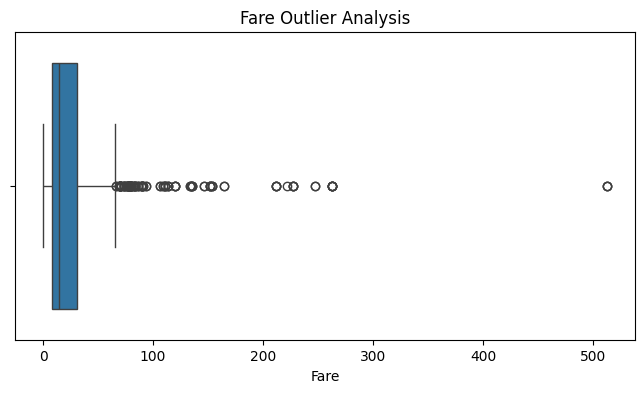

In [38]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df['Fare'])

plt.title('Fare Outlier Analysis')
plt.xlabel('Fare')

plt.show()

In [39]:
numeric_summary = df[
    ['Age', 'Fare', 'SibSp', 'Parch', 'FamilySize']
].describe().T

numeric_summary

,count,mean,std,min,25%,50%,75%,max
Age,891.0,29.699118,13.002015,0.42,22.0000,29.699118,35.0,80.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.454200,31.0,512.3292
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.000000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.000000,0.0,6.0000
FamilySize,891.0,1.904602,1.613459,1.00,1.0000,1.000000,2.0,11.0000


In [40]:
categorical_summary = pd.DataFrame({
    'Unique Values': df[['Sex', 'Embarked', 'Pclass']].nunique(),
    'Most Frequent': [
        df['Sex'].mode()[0],
        df['Embarked'].mode()[0],
        df['Pclass'].mode()[0]
    ]
})

categorical_summary

,Unique Values,Most Frequent
Sex,2,male
Embarked,3,S
Pclass,3,3


## Key EDA Findings

Based on the exploratory analysis:

1. The dataset contains 891 passenger records and includes both numerical and categorical variables.

2. Cabin has a very high percentage of missing observations, making direct imputation unreliable. Therefore, it was removed during preprocessing.

3. Age contains a considerable number of missing observations and requires imputation before machine-learning modelling.

4. Embarked has only a very small number of missing observations and is imputed using its mode.

5. Survival is not uniformly distributed across all passenger groups. Survival rates vary across gender and passenger class.

6. Passenger class shows an important relationship with survival, which can be investigated through grouped survival percentages.

7. Age distributions differ between passengers who survived and passengers who did not survive.

8. Fare shows substantial variation and contains high-value observations that can be identified through boxplot analysis.

9. Family size can be derived from SibSp and Parch and provides an additional feature for understanding passenger survival patterns.

10. Correlation analysis provides an overview of relationships among numerical variables and helps identify potentially useful features for predictive modelling.

The EDA therefore provides evidence-based insights that can guide feature selection and subsequent machine-learning modelling.

In [41]:
#Normalization
df1 = pd.read_csv('wine_data.csv',header=None,usecols=[0,1,2])
df1.columns=['Class label', 'Alcohol', 'Malic acid']

In [42]:
df1.head()

,Class label,Alcohol,Malic acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59


<Axes: xlabel='Alcohol', ylabel='Density'>

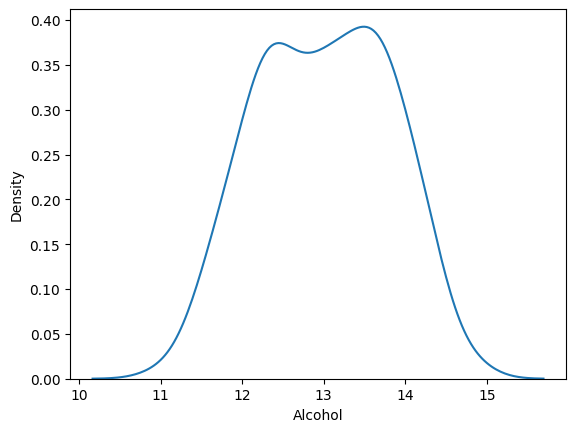

In [43]:
sns.kdeplot(df1['Alcohol'])

<Axes: xlabel='Malic acid', ylabel='Density'>

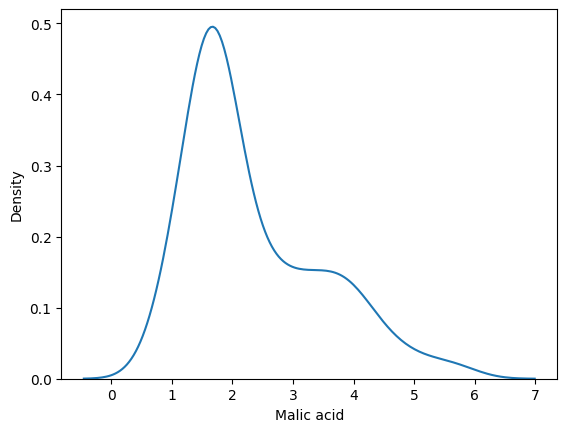

In [44]:
sns.kdeplot(df1['Malic acid'])

In [45]:
X_train, X_test, y_train, y_test = train_test_split(df1.drop('Class label', axis=1),
                                                    df1['Class label'],
                                                    test_size=0.3,
                                                    random_state=0)

X_train.shape, X_test.shape

((124, 2), (54, 2))

In [46]:
scaler = MinMaxScaler()

# fit the scaler to the train set, it will learn the parameters
scaler.fit(X_train)

# transform train and test sets
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [47]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

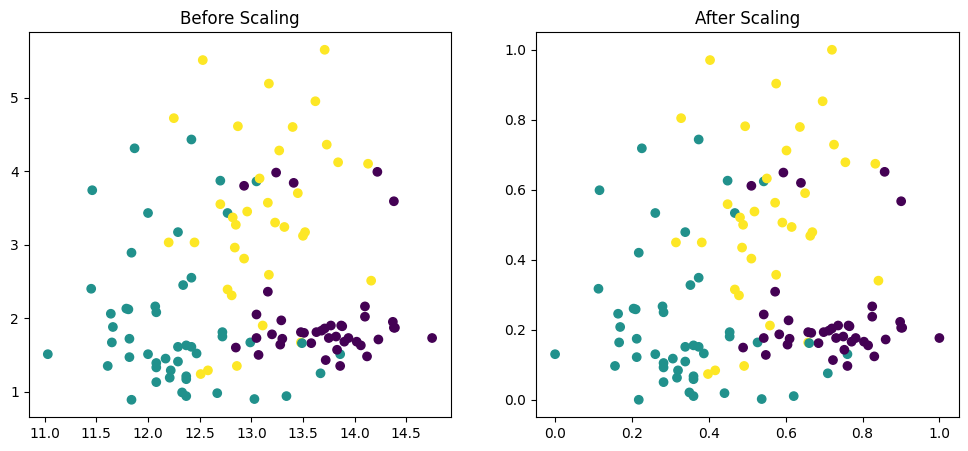

In [48]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(X_train['Alcohol'], X_train['Malic acid'],c=y_train)
ax1.set_title("Before Scaling")
ax2.scatter(X_train_scaled['Alcohol'], X_train_scaled['Malic acid'],c=y_train)
ax2.set_title("After Scaling")
plt.show()

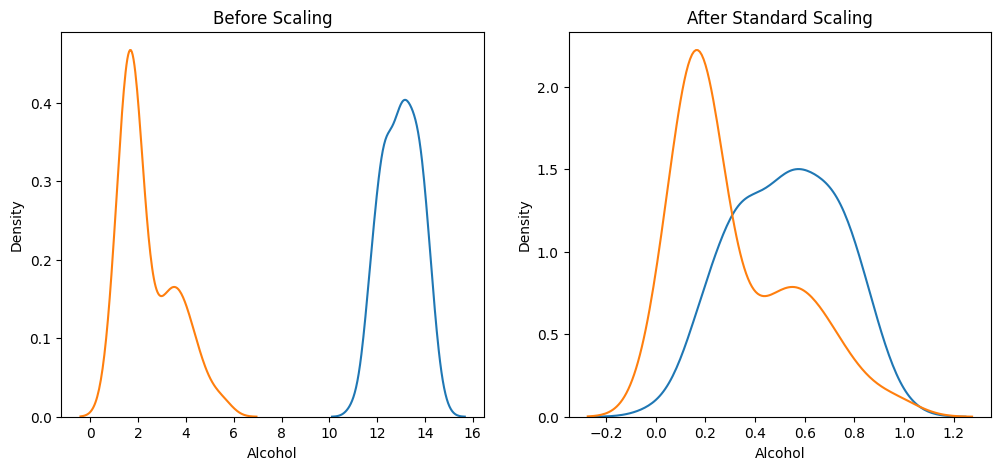

In [49]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax1.set_title('Before Scaling')
sns.kdeplot(X_train['Alcohol'], ax=ax1)
sns.kdeplot(X_train['Malic acid'], ax=ax1)

# after scaling
ax2.set_title('After Standard Scaling')
sns.kdeplot(X_train_scaled['Alcohol'], ax=ax2)
sns.kdeplot(X_train_scaled['Malic acid'], ax=ax2)
plt.show()